# 1. Parsowanie Plików

## Modele Danych

In [1]:
from IPython import display

from BayesianNetwork.models import graph
from BayesianNetwork.models.data import Data
from BayesianNetwork.models.graph import GraphData
from BayesianNetwork.models.variable import Variable
from BayesianNetwork.models.queries import Query, QueryType

## Wybór katalogu danych


In [2]:
import os
REPO = "k12"

data_path = os.path.join('..', 'data', 'zestawy', REPO)
files = os.listdir(data_path)

files

['zapytania.txt', 'dane.csv', 'test.csv', 'ograniczenia.txt', 'opis.json']

## Parsowanie do odpowiednich Modeli

In [3]:
from BayesianNetwork.parsing.description_parsing import description_parser
from rich import print as rprint

desc_path = os.path.join(data_path, 'opis.json')
graf = description_parser(desc_path)

rprint(graf)

GraphData(
    variables_dict={
        'D': Variable(name='D', description='trudność kursu', states=['Easy', 'Hard']),
        'I': Variable(name='I', description='zdolności studenta', states=['Dumb', 'Intelligent']),
        'M': Variable(name='M', description='motywacja studenta', states=['Low', 'High']),
        'W': Variable(name='W', description='praca zarobkowa w trakcie studiów', states=['No', 'Yes']),
        'A': Variable(name='A', description='frekwencja na zajęciach', states=['Low', 'Medium', 'High']),
        'G': Variable(name='G', description='ocena z kursu', states=['A', 'B', 'C']),
        'S': Variable(name='S', description='wynik testu SAT', states=['Bad', 'Good']),
        'L': Variable(name='L', description='list polecający', states=['Bad', 'Good']),
        'B': Variable(name='B', description='stypendium naukowe', states=['No', 'Yes'])
    },
    exper_edges=[
        ('A', 'L'),
        ('D', 'A'),
        ('D', 'G'),
        ('G', 'B'),
        ('G', 'L'),
        ('I', 'D'),
        ('I', 'G'),
        ('I', 'L'),
        ('I', 'S'),
        ('M', 'G'),
        ('M', 'S'),
        ('W', 'A')
    ],
    required_edges=[('D', 'G'), ('G', 'L'), ('I', 'G'), ('I', 'S')],
    forbidden_edges=[('A', 'G'), ('B', 'L'), ('D', 'B'), ('M', 'B')],
    tiers=[['D', 'I', 'M', 'W'], ['A'], ['G', 'S'], ['L', 'B']]
)

In [4]:
from BayesianNetwork.parsing.data_parsing import parse_data

variables = graf.variables_dict
train_data_path = os.path.join(data_path, 'dane.csv')
train =  parse_data(
    path = train_data_path,
    variables = variables,
    is_train_data=True,
    allow_missing=True
)

print(train.data_purpose)
train.data_frame

DataPurpose.Train


/tmp/ipykernel_25791/1303061874.py:5: UserWarning: Train data contains 4740 nans
  train =  parse_data(


,D,I,M,W,A,G,S,L,B
0,Easy,NaN,NaN,No,High,B,Bad,Bad,No
1,Easy,Dumb,NaN,No,Medium,A,Bad,NaN,Yes
2,NaN,Dumb,Low,NaN,Low,C,Bad,Bad,No
3,Easy,NaN,High,No,NaN,NaN,Bad,Good,Yes
4,Hard,NaN,High,No,Medium,C,Bad,Bad,No
...,...,...,...,...,...,...,...,...,...
2995,Easy,NaN,Low,Yes,Medium,C,Bad,Bad,No
2996,Easy,NaN,High,No,High,A,Bad,NaN,Yes
2997,Easy,NaN,High,NaN,Medium,A,NaN,Good,Yes
2998,Hard,NaN,High,No,Low,C,NaN,Bad,No


In [5]:
test_data_path = os.path.join(data_path, 'test.csv')
test = parse_data(
    path = test_data_path,
    variables = variables,
    is_train_data=False,
    allow_missing=False
)

print(test.data_purpose)
test.data_frame

DataPurpose.Test


,D,I,M,W,A,G,S,L,B
0,Easy,Dumb,High,Yes,High,A,Bad,Good,Yes
1,Hard,Dumb,Low,Yes,Low,C,Bad,Bad,No
2,Hard,Dumb,Low,No,Low,C,Bad,Bad,No
3,Easy,Dumb,High,No,High,A,Bad,Good,Yes
4,Hard,Dumb,Low,No,Low,C,Good,Bad,No
...,...,...,...,...,...,...,...,...,...
1995,Hard,Dumb,Low,Yes,Medium,C,Bad,Bad,No
1996,Hard,Intelligent,Low,No,Low,A,Bad,Good,Yes
1997,Hard,Dumb,High,No,Low,C,Bad,Bad,No
1998,Easy,Dumb,High,No,High,A,Bad,Good,Yes


In [6]:
from BayesianNetwork.parsing.query_parsing import query_parser
queries = query_parser(
    path=os.path.join(data_path, 'zapytania.txt'),
    variables_dict=variables,
)

queries

[Query(query_type=<QueryType.P: 1>, variables=['G'], evidence={}),
 Query(query_type=<QueryType.P: 1>, variables=['L'], evidence={}),
 Query(query_type=<QueryType.P: 1>, variables=['I'], evidence={}),
 Query(query_type=<QueryType.P: 1>, variables=['B'], evidence={}),
 Query(query_type=<QueryType.P: 1>, variables=['G'], evidence={'D': 'Hard', 'I': 'Intelligent'}),
 Query(query_type=<QueryType.P: 1>, variables=['G'], evidence={'D': 'Easy', 'I': 'Dumb'}),
 Query(query_type=<QueryType.P: 1>, variables=['I'], evidence={'G': 'A', 'S': 'Good'}),
 Query(query_type=<QueryType.P: 1>, variables=['I'], evidence={'G': 'C'}),
 Query(query_type=<QueryType.P: 1>, variables=['I'], evidence={'G': 'C', 'D': 'Hard'}),
 Query(query_type=<QueryType.P: 1>, variables=['D'], evidence={'G': 'C'}),
 Query(query_type=<QueryType.P: 1>, variables=['G', 'L'], evidence={'S': 'Good'}),
 Query(query_type=<QueryType.P: 1>, variables=['G'], evidence={'M': 'High'}),
 Query(query_type=<QueryType.P: 1>, variables=['M'], evi

# 2. Sieć z Grafu Eksperckiego

In [7]:
from BayesianNetwork.network.MyNetworkClass import MyNetworkClass

network_obj = MyNetworkClass.build_from_expert_graph(
    graph = graf,
    training_data= train
)

network_obj

/home/kendama/Projects/University_Classes/SEM_5/IFM_konwoledge_enginnering/.venv/lib/python3.13/site-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


In [8]:
network_obj.network.get_roots()

['I', 'M', 'W']

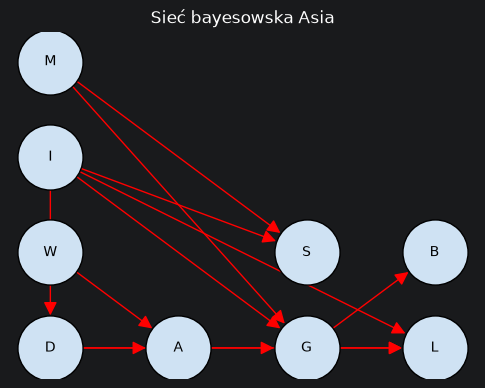

In [9]:
import matplotlib.pyplot as plt
import networkx as nx

pos = {
    # Tier 1
    "D": (1, 1),
    "W": (1, 2),
    "I": (1, 3),
    "M": (1, 4),

    # Tier 2
    "A": (2, 1),

    #Tier 3
    "G": (3, 1),
    "S": (3, 2),

    # Tier 4
    "L": (4, 1),
    "B": (4, 2),
}


plt.figure(figsize=(6, 4.5))
nx.draw_networkx(network_obj.network, pos=pos, node_size=2200, node_color="#cfe2f3", edge_color="red",
                 edgecolors="k", arrowsize=20, font_size=10)
plt.axis("off")
plt.title("Sieć bayesowska Asia")
plt.show()


## 2.1 Największa tablica CDP

In [10]:
network_obj.network

In [11]:
biggest_cdp = network_obj.get_biggest_cdp()

biggest_cdp.to_dataframe()

L                          Bad      Good
A      G I                              
High   A Dumb         0.088050  0.911950
         Intelligent  0.025000  0.975000
       B Dumb         0.538462  0.461538
         Intelligent  0.000000  1.000000
       C Dumb         0.927711  0.072289
         Intelligent  0.000000  1.000000
Low    A Dumb         0.515152  0.484848
         Intelligent  0.060241  0.939759
       B Dumb         0.850000  0.150000
         Intelligent  0.372093  0.627907
       C Dumb         0.969466  0.030534
         Intelligent  0.913043  0.086957
Medium A Dumb         0.153846  0.846154
         Intelligent  0.000000  1.000000
       B Dumb         0.625000  0.375000
         Intelligent  0.200000  0.800000
       C Dumb         0.968750  0.031250
         Intelligent  0.777778  0.222222

## 2.2 Ile konfiguracji rodziców nie ma jednego wiersza?
W obecnej wersji pgmpy DiscreteMLE zamienia kolumnę z samymi zerami na jedynki, a następnie normalizuje. Czyli dla konfiguracji bez danych wpisuje rozkład jednostajny: każda wartość węzła dostaje prawdopodobieństwo 1 / liczba_stanów.

In [12]:
from itertools import product
import numpy as np

df = train.data_frame

for node in network_obj.network.nodes():
    cpd = network_obj.network.get_cpds(node)
    parents = cpd.variables[1:]  # kolejność rodziców używana przez tę CPD
    if not parents:
        continue

    configurations = list(product(*(cpd.state_names[p] for p in parents)))
    table = cpd.get_values()
    absent = []

    for column, config in enumerate(configurations):
        mask = np.ones(len(df), dtype=bool)

        for parent, state in zip(parents, config):
            mask &= df[parent].eq(state).to_numpy()

        parent_rows = int(mask.sum())
        complete_rows = int((mask & df[node].notna().to_numpy()).sum())

        if parent_rows == 0:
            absent.append((column, config, parent_rows, complete_rows))

    print(f"{node}: brak wierszy dla {len(absent)} z {len(configurations)} konfiguracji rodziców")

    for column, config, _, _ in absent:
        probabilities = dict(zip(cpd.state_names[node], table[:, column]))
        print(f"  {dict(zip(parents, config))} -> {probabilities}")

A: brak wierszy dla 0 z 4 konfiguracji rodziców
L: brak wierszy dla 0 z 18 konfiguracji rodziców
D: brak wierszy dla 0 z 2 konfiguracji rodziców
G: brak wierszy dla 0 z 8 konfiguracji rodziców
B: brak wierszy dla 0 z 3 konfiguracji rodziców
S: brak wierszy dla 0 z 4 konfiguracji rodziców


# 3. Zapytania

In [13]:
for q in queries:
    ans = network_obj.answer_question(query=q)
    print(q)
    print(ans)
    print()

Query(query_type=<QueryType.P: 1>, variables=['G'], evidence={})
+------+----------+
| G    |   phi(G) |
+======+==========+
| G(A) |   0.4328 |
+------+----------+
| G(B) |   0.1901 |
+------+----------+
| G(C) |   0.3771 |
+------+----------+

Query(query_type=<QueryType.P: 1>, variables=['L'], evidence={})
+---------+----------+
| L       |   phi(L) |
+=========+==========+
| L(Bad)  |   0.5016 |
+---------+----------+
| L(Good) |   0.4984 |
+---------+----------+

Query(query_type=<QueryType.P: 1>, variables=['I'], evidence={})
+----------------+----------+
| I              |   phi(I) |
+================+==========+
| I(Dumb)        |   0.7149 |
+----------------+----------+
| I(Intelligent) |   0.2851 |
+----------------+----------+

Query(query_type=<QueryType.P: 1>, variables=['B'], evidence={})
+--------+----------+
| B      |   phi(B) |
+========+==========+
| B(No)  |   0.5433 |
+--------+----------+
| B(Yes) |   0.4567 |
+--------+----------+

Query(query_type=<QueryType.P: 

# 4. Ocena Modelu

In [14]:
#TODO: Oceń model na test.csv


